# Analisis Statistika Deskriptif Nilai Diskon, Berat Pengiriman, dan Kuantitas Pembelian pada Transaksi E-Commerce Indonesia Tahun 2024–2025

**Mata kuliah:** Probabilitas dan Statistika · **Kelompok:** 3TIA-08
**Sumber data:** Kaggle – *Indonesia E-Commerce Sales and Shipping 2023–2025* (data sekunder, n = 500 transaksi, 8 variabel)

Notebook ini **hanya memuat statistika deskriptif**: deskripsi data, tabel dan grafik, ukuran pemusatan, ukuran letak, ukuran penyebaran, dan ukuran bentuk sebaran.

| Variabel utama | Tipe data | Jenis | Skala | Satuan |
|---|---|---|---|---|
| `Nilai_Diskon_Rp` | Kuantitatif | Kontinu | Rasio | Rupiah |
| `Berat_Pengiriman_Gram` | Kuantitatif | Kontinu | Rasio | Gram |
| `Kuantitas_Pembelian_Pcs` | Kuantitatif | Diskrit | Rasio | Pcs |

**Rumusan masalah**
1. Bagaimana karakteristik statistika deskriptif (rata-rata, variansi, standar deviasi) dari nilai diskon, berat pengiriman, dan kuantitas pembelian pada transaksi e-commerce Indonesia tahun 2024–2025?
2. Bagaimana bentuk distribusi frekuensi kuantitas pembelian konsumen dalam satu transaksi?
3. Bagaimana ukuran letak (kuartil, jangkauan antarkuartil, nilai minimum, dan nilai maksimum) dari nilai diskon, berat pengiriman, dan kuantitas pembelian?

> **Cara pakai:** pilih `Runtime → Run all`, lalu unggah file Excel saat diminta. Semua gambar tersimpan di folder `output_laporan/` dan ikut terunduh di akhir.

<a name="menu"></a>

## 📑 MENU — klik untuk langsung menuju bagian

| Tahap | Isi | RM | Laporan | Output | Langkah |
|---|---|---|---|---|---|
| [**Tahap 0**](#tahap0) | Persiapan | – | – | – | – |
| [**Tahap 1**](#tahap1) | Deskripsi dan gambaran umum data | – | 4.1 | Tabel 4.1, Gambar 4.1–4.2 | [1.1](#langkah11) · [1.2](#langkah12) · [1.3](#langkah13) · [1.4](#langkah14) |
| [**Tahap 2**](#tahap2) | Resume statistika deskriptif; rata-rata, variansi, standar deviasi | RM 1 | 4.2–4.3 | Tabel 4.2, Gambar 4.3–4.4 | [2.1](#langkah21) · [2.2](#langkah22) · [2.3](#langkah23) · [2.4](#langkah24) |
| [**Tahap 3**](#tahap3) | Distribusi frekuensi kuantitas pembelian | RM 2 | 4.4 | Tabel 4.3, Gambar 4.5 | [3.1](#langkah31) · [3.2](#langkah32) · [3.3](#langkah33) |
| [**Tahap 4**](#tahap4) | Ukuran letak | RM 3 | 4.5 | Gambar 4.6 | [4.1](#langkah41) · [4.2](#langkah42) · [4.3](#langkah43) |
| [**Tahap 5**](#tahap5) | Dashboard dan menu interaktif | Semua | 4.6 | Gambar 4.7 | [5.1](#langkah51) · [**5.2 Dashboard interaktif**](#langkah52) |
| [**Tahap 6**](#tahap6) | Ringkasan jawaban dan ekspor file | Semua | 4.7, Bab 5 | Excel + ZIP | [6.1](#langkah61) · [6.2](#langkah62) |

Nomor gambar dan tabel sama dengan nomor di laporan. Panel **Daftar isi** (ikon ☰ di kiri Colab) juga bisa dipakai untuk berpindah bagian.

---
<a name="tahap0"></a>

## TAHAP 0 — Persiapan

<a href="#menu">⬆ Kembali ke MENU</a>

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("output_laporan", exist_ok=True)

VAR = ["Nilai_Diskon_Rp", "Berat_Pengiriman_Gram", "Kuantitas_Pembelian_Pcs"]   # tiga variabel utama
NAMA = {"Nilai_Diskon_Rp": "Nilai Diskon (Rp)", "Berat_Pengiriman_Gram": "Berat Pengiriman (Gram)",
        "Kuantitas_Pembelian_Pcs": "Kuantitas Pembelian (Pcs)"}
WARNA = {"Nilai_Diskon_Rp": "#2E86AB", "Berat_Pengiriman_Gram": "#F18F01", "Kuantitas_Pembelian_Pcs": "#C73E1D"}

def simpan(fig, nama):                     # simpan gambar untuk laporan
    fig.savefig(f"output_laporan/{nama}.png", dpi=300, bbox_inches="tight")

def idn(x, d=2):                           # format angka Indonesia: 12345.6 -> 12.345,60
    return f"{x:,.{d}f}".replace(",", "#").replace(".", ",").replace("#", ".")

---
<a name="tahap1"></a>

## TAHAP 1 — Deskripsi dan Gambaran Umum Data (Laporan 4.1)

<a href="#menu">⬆ Kembali ke MENU</a>
<a name="langkah11"></a>

### Langkah 1.1 — Upload file Excel

In [2]:
NAMA_FILE = "3TIA_08_ECommerce_Indonesia_Kaggle_2024_2025.xlsx"
if not os.path.exists(NAMA_FILE):          # di Colab: pilih file Excel saat tombol upload muncul
    from google.colab import files
    NAMA_FILE = list(files.upload())[0]

Saving 3TIA_08_ECommerce_Indonesia_Kaggle_2024_2025.xlsx to 3TIA_08_ECommerce_Indonesia_Kaggle_2024_2025.xlsx


<a name="langkah12"></a>

### Langkah 1.2 — Membaca data dan kamus data (deskripsi variabel dan tipe data)

In [3]:
df = pd.read_excel(NAMA_FILE, sheet_name="Dataset_Bersih")
kamus = pd.read_excel(NAMA_FILE, sheet_name="Kamus_Data")
df["Tanggal_Transaksi"] = pd.to_datetime(df["Tanggal_Transaksi"])
n = len(df)

print("Ukuran data:", df.shape)
display(kamus)
display(df.head(10))

Ukuran data: (500, 8)


,Nama Variabel,Deskripsi Variabel,Peran Variabel,Tipe Data,Jenis Data,Skala Pengukuran,Satuan / Format
0,ID_Transaksi,Kode unik identitas transaksi e-commerce,Identifikasi,Kualitatif,Diskrit,Nominal,TRX_2024000001 s.d TRX_2024000500
1,Tanggal_Transaksi,Tanggal terjadinya transaksi pembelian,Pendukung,Kualitatif,Diskrit,Ordinal,YYYY-MM-DD (2024 - 2025)
2,Provinsi_Tujuan,Provinsi lokasi pengiriman pesanan,Pendukung,Kualitatif,Diskrit,Nominal,"DKI Jakarta, Jawa Barat, Riau, dll."
3,Kategori_Produk,Kategori jenis barang yang dibeli,Pendukung,Kualitatif,Diskrit,Nominal,"Pakaian, Elektronik, Kecantikan, dll."
4,Berat_Pengiriman_Gram,Berat total barang yang dikirim dalam gram,Variabel Utama,Kuantitatif,Kontinu,Rasio,Gram (gr)
5,Nilai_Diskon_Rp,Besar potongan harga / diskon yang didapat,Variabel Utama,Kuantitatif,Kontinu,Rasio,Rupiah (Rp)
6,Kuantitas_Pembelian_Pcs,Jumlah unit produk yang dibeli konsumen,Variabel Utama,Kuantitatif,Diskrit,Rasio,Pieces (Pcs)
7,Total_Nilai_Belanja_Rp,Total nominal transaksi sebelum diskon,Variabel Pendukung,Kuantitatif,Kontinu,Rasio,Rupiah (Rp)


,ID_Transaksi,Tanggal_Transaksi,Provinsi_Tujuan,Kategori_Produk,Berat_Pengiriman_Gram,Nilai_Diskon_Rp,Kuantitas_Pembelian_Pcs,Total_Nilai_Belanja_Rp
0,TRX_2024001,2024-01-01,DKI Jakarta,Kecantikan & Perawatan,3097,15000,3,135000
1,TRX_2024002,2024-01-02,Sumatera Utara,Pakaian & Fashion,435,5000,2,300000
2,TRX_2024003,2024-01-03,Banten,Elektronik & Gadget,3225,35000,4,340000
3,TRX_2024004,2024-01-05,Jawa Barat,Elektronik & Gadget,436,10000,6,270000
4,TRX_2024005,2024-01-06,Jawa Barat,Kebutuhan Rumah Tangga,2560,20000,4,180000
5,TRX_2024006,2024-01-08,Jawa Barat,Pakaian & Fashion,2220,15000,4,340000
6,TRX_2024007,2024-01-09,Jawa Timur,Elektronik & Gadget,2135,25000,3,135000
7,TRX_2024008,2024-01-11,Jawa Tengah,Kecantikan & Perawatan,3785,5000,3,255000
8,TRX_2024009,2024-01-12,Banten,Kecantikan & Perawatan,2061,20000,3,1050000
9,TRX_2024010,2024-01-14,Riau,Elektronik & Gadget,3015,5000,1,85000


<a name="langkah13"></a>

### Langkah 1.3 — Ringkasan deskripsi data → **Tabel 4.1**

In [4]:
ringkasan = {
    "Jumlah baris (transaksi)": n,
    "Jumlah kolom (variabel)": df.shape[1],
    "Nilai kosong (seluruh kolom)": df.isna().sum().sum(),
    "Baris duplikat": df.duplicated().sum(),
    "ID transaksi ganda": df["ID_Transaksi"].duplicated().sum(),
    "Nilai negatif pada variabel utama": (df[VAR] < 0).sum().sum(),
    "Rentang ID transaksi": f"{df['ID_Transaksi'].min()} s.d. {df['ID_Transaksi'].max()}",
    "Rentang tanggal transaksi": f"{df['Tanggal_Transaksi'].min():%d-%m-%Y} s.d. {df['Tanggal_Transaksi'].max():%d-%m-%Y}",
    "Jumlah kategori produk": df["Kategori_Produk"].nunique(),
    "Jumlah provinsi tujuan": df["Provinsi_Tujuan"].nunique()}
for k in VAR:
    ringkasan[f"Banyak nilai berbeda: {k}"] = df[k].nunique()
tabel_4_1 = pd.DataFrame(ringkasan.items(), columns=["Pemeriksaan", "Hasil"])
display(tabel_4_1)

,Pemeriksaan,Hasil
0,Jumlah baris (transaksi),500
1,Jumlah kolom (variabel),8
2,Nilai kosong (seluruh kolom),0
3,Baris duplikat,0
4,ID transaksi ganda,0
5,Nilai negatif pada variabel utama,0
6,Rentang ID transaksi,TRX_2024001 s.d. TRX_2024500
7,Rentang tanggal transaksi,01-01-2024 s.d. 31-12-2025
8,Jumlah kategori produk,5
9,Jumlah provinsi tujuan,8


<a name="langkah14"></a>

### Langkah 1.4 — Gambaran umum data → **Gambar 4.1** dan **Gambar 4.2**

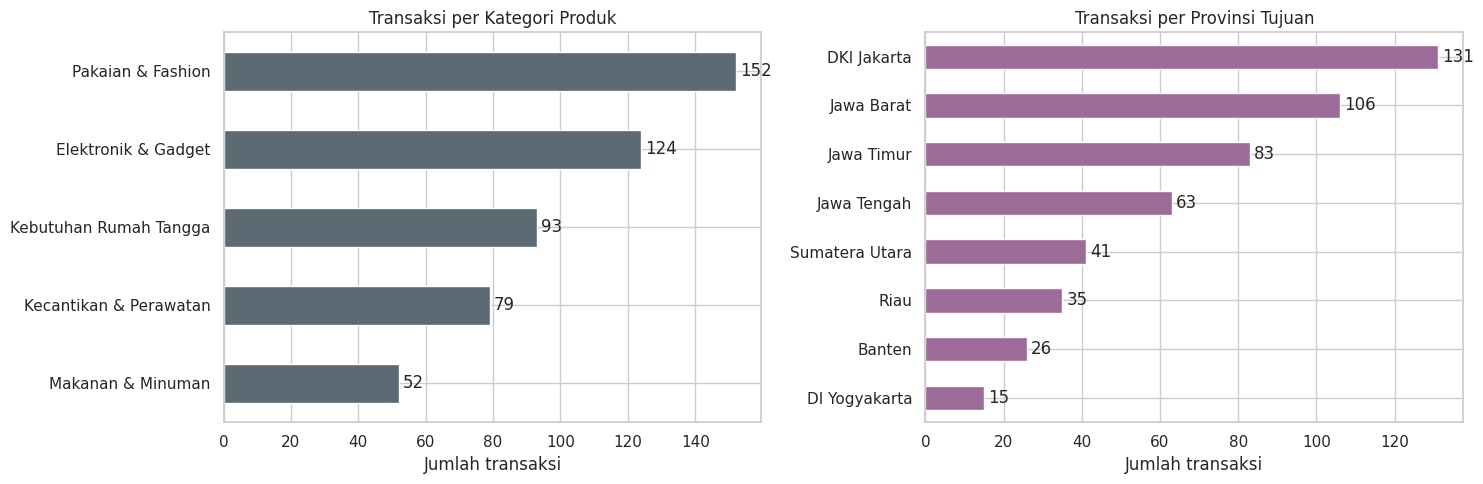

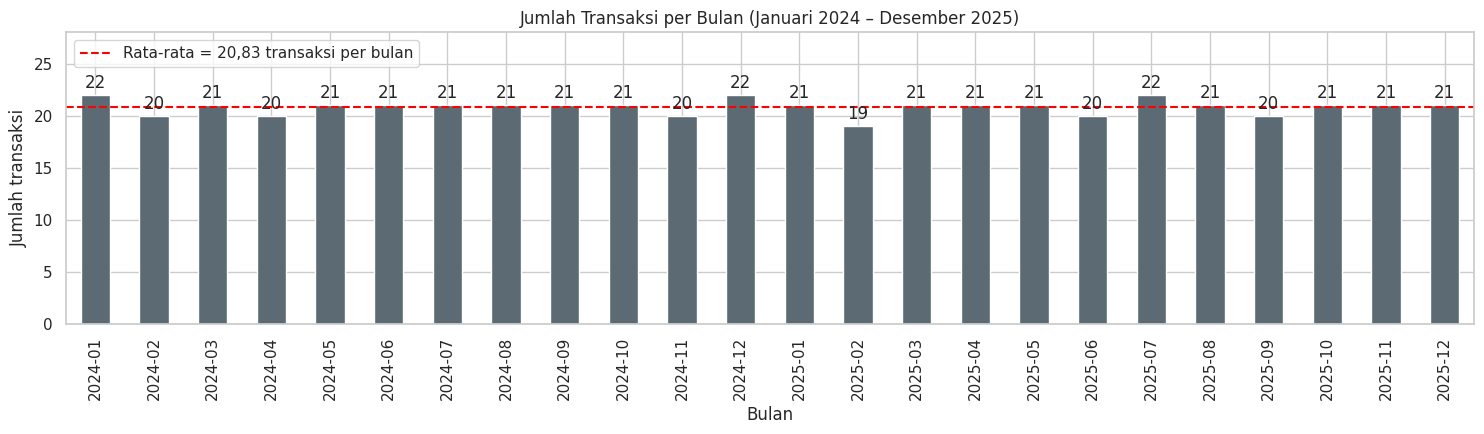

Kategori_Produk
Pakaian & Fashion         152
Elektronik & Gadget       124
Kebutuhan Rumah Tangga     93
Kecantikan & Perawatan     79
Makanan & Minuman          52
Name: count, dtype: int64 

Provinsi_Tujuan
DKI Jakarta       131
Jawa Barat        106
Jawa Timur         83
Jawa Tengah        63
Sumatera Utara     41
Riau               35
Banten             26
DI Yogyakarta      15
Name: count, dtype: int64 

Transaksi per bulan: 19–22, rata-rata 20,83


In [5]:
# Gambar 4.1: frekuensi transaksi per kategori produk dan per provinsi tujuan
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
df["Kategori_Produk"].value_counts().sort_values().plot.barh(ax=ax[0], color="#5C6B73")
df["Provinsi_Tujuan"].value_counts().sort_values().plot.barh(ax=ax[1], color="#9C6B98")
ax[0].set_title("Transaksi per Kategori Produk"); ax[1].set_title("Transaksi per Provinsi Tujuan")
for a in ax:
    a.bar_label(a.containers[0], padding=3); a.set_xlabel("Jumlah transaksi"); a.set_ylabel("")
plt.tight_layout(); simpan(fig, "Gambar_4.1_Komposisi_Kategori_Provinsi"); plt.show()

# Gambar 4.2: jumlah transaksi per bulan
per_bulan = df.groupby(df["Tanggal_Transaksi"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(15, 4.5))
per_bulan.plot.bar(ax=ax, color="#5C6B73")
ax.bar_label(ax.containers[0], padding=2)
ax.axhline(per_bulan.mean(), color="red", ls="--", label=f"Rata-rata = {idn(per_bulan.mean())} transaksi per bulan")
ax.set_title("Jumlah Transaksi per Bulan (Januari 2024 – Desember 2025)")
ax.set_xlabel("Bulan"); ax.set_ylabel("Jumlah transaksi"); ax.set_ylim(0, 28); ax.legend(loc="upper left")
plt.tight_layout(); simpan(fig, "Gambar_4.2_Jumlah_Transaksi_per_Bulan"); plt.show()

print(df["Kategori_Produk"].value_counts(), "\n")
print(df["Provinsi_Tujuan"].value_counts(), "\n")
print(f"Transaksi per bulan: {per_bulan.min()}–{per_bulan.max()}, rata-rata {idn(per_bulan.mean())}")

---
<a name="tahap2"></a>

## TAHAP 2 — Resume Statistika Deskriptif dan Jawaban RM 1 (Laporan 4.2–4.3)

<a href="#menu">⬆ Kembali ke MENU</a>
<a name="langkah21"></a>

### Langkah 2.1 — Tabel resume statistika deskriptif → **Tabel 4.2**
Semua ukuran yang diminta: count, jumlah, rata-rata, median (Q2), modus, *standard error*, variansi, standar deviasi, minimum, Q1, Q3, maksimum, jangkauan, IQR, koefisien variasi, *skewness*, dan *kurtosis*.

In [6]:
def resume(x):
    q1, q2, q3 = x.quantile([0.25, 0.50, 0.75])
    return pd.Series({
        "Banyak data (count)": x.count(),
        "Jumlah (Σx)": x.sum(),
        "Rata-rata (x̄)": x.mean(),
        "Median (Q2)": q2,
        "Modus": x.mode()[0],
        "Standard error (SE)": x.std() / np.sqrt(x.count()),
        "Variansi (s²)": x.var(),
        "Standar deviasi (s)": x.std(),
        "Minimum": x.min(),
        "Kuartil pertama (Q1)": q1,
        "Kuartil ketiga (Q3)": q3,
        "Maksimum": x.max(),
        "Jangkauan (range)": x.max() - x.min(),
        "Jangkauan antarkuartil (IQR)": q3 - q1,
        "Koefisien variasi (%)": x.std() / x.mean() * 100,
        "Kemencengan (skewness)": x.skew(),
        "Keruncingan (kurtosis)": x.kurt()})

tabel_4_2 = df[VAR].apply(resume)
display(tabel_4_2.map(lambda v: idn(v, 3)))

for k in VAR:                              # modus bisa lebih dari satu nilai
    print(f"Modus {k}: {df[k].mode().tolist()}")

,Nilai_Diskon_Rp,Berat_Pengiriman_Gram,Kuantitas_Pembelian_Pcs
Banyak data (count),"500,000","500,000","500,000"
Jumlah (Σx),"13.255.000,000","1.159.227,000","1.767,000"
Rata-rata (x̄),"26.510,000","2.318,454","3,534"
Median (Q2),"20.000,000","2.312,500","3,000"
Modus,"10.000,000","265,000","2,000"
Standard error (SE),"1.130,352","55,834","0,074"
Variansi (s²),"638.847.595,190","1.558.698,629","2,730"
Standar deviasi (s),"25.275,435","1.248,479","1,652"
Minimum,"5.000,000","218,000","1,000"
Kuartil pertama (Q1),"10.000,000","1.260,750","2,000"


Modus Nilai_Diskon_Rp: [10000]
Modus Berat_Pengiriman_Gram: [265, 2309]
Modus Kuantitas_Pembelian_Pcs: [2]


<a name="langkah22"></a>

### Langkah 2.2 — Perhitungan manual rata-rata, variansi, standar deviasi, dan *standard error*
$\bar{x} = \dfrac{\sum x}{n}$, $\quad s^2 = \dfrac{\sum (x-\bar{x})^2}{n-1}$, $\quad s = \sqrt{s^2}$, $\quad SE = \dfrac{s}{\sqrt{n}}$, $\quad CV = \dfrac{s}{\bar{x}} \times 100\%$

In [7]:
for k in VAR:
    x = df[k]
    rata = x.sum() / n
    jk = ((x - rata) ** 2).sum()             # jumlah kuadrat simpangan
    var = jk / (n - 1)
    sd = np.sqrt(var)
    print(NAMA[k])
    print(f"  Σx = {idn(x.sum(), 0)}  →  x̄ = {idn(x.sum(), 0)} / {n} = {idn(rata, 4)}")
    print(f"  Σ(x − x̄)² = {idn(jk, 4)}  →  s² = {idn(jk, 4)} / {n - 1} = {idn(var, 4)}")
    print(f"  s = √s² = {idn(sd, 4)}  |  SE = s / √n = {idn(sd / np.sqrt(n), 4)}  |  CV = {idn(sd / rata * 100, 2)}%\n")

Nilai Diskon (Rp)
  Σx = 13.255.000  →  x̄ = 13.255.000 / 500 = 26.510,0000
  Σ(x − x̄)² = 318.784.950.000,0000  →  s² = 318.784.950.000,0000 / 499 = 638.847.595,1904
  s = √s² = 25.275,4346  |  SE = s / √n = 1.130,3518  |  CV = 95,34%

Berat Pengiriman (Gram)
  Σx = 1.159.227  →  x̄ = 1.159.227 / 500 = 2.318,4540
  Σ(x − x̄)² = 777.790.615,9420  →  s² = 777.790.615,9420 / 499 = 1.558.698,6291
  s = √s² = 1.248,4785  |  SE = s / √n = 55,8337  |  CV = 53,85%

Kuantitas Pembelian (Pcs)
  Σx = 1.767  →  x̄ = 1.767 / 500 = 3,5340
  Σ(x − x̄)² = 1.362,4220  →  s² = 1.362,4220 / 499 = 2,7303
  s = √s² = 1,6524  |  SE = s / √n = 0,0739  |  CV = 46,76%



<a name="langkah23"></a>

### Langkah 2.3 — Histogram → **Gambar 4.3**
Garis merah putus-putus = rata-rata, garis hitam = median.

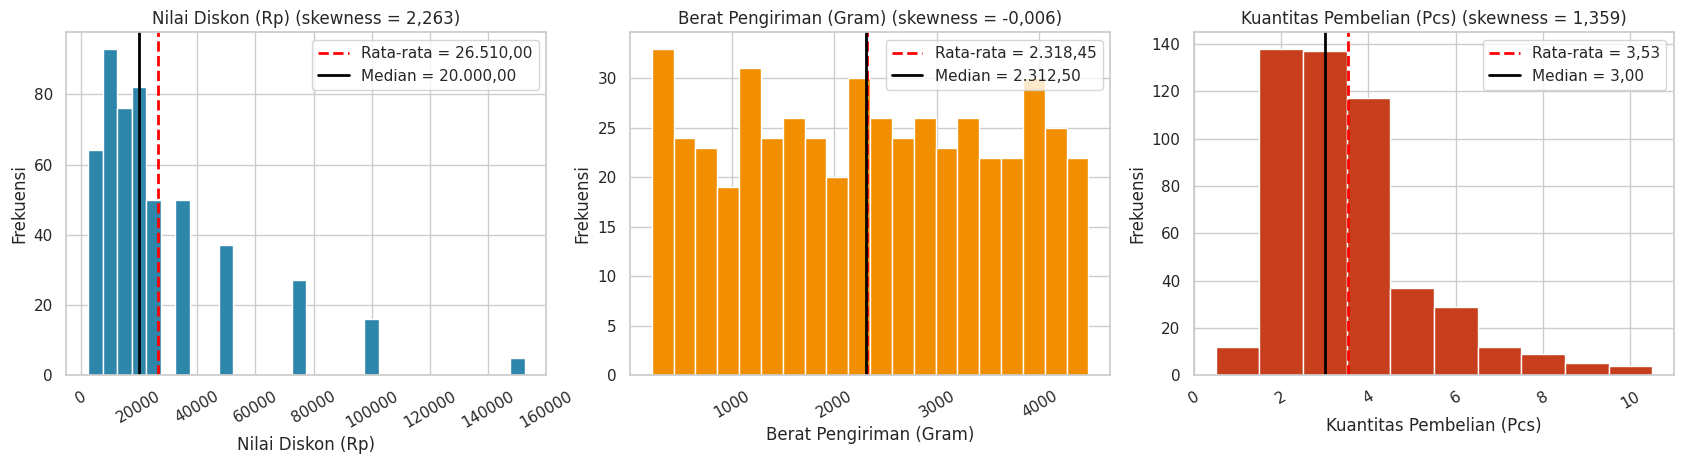

In [8]:
KELAS = {"Nilai_Diskon_Rp": np.arange(2500, 157500, 5000),        # satu batang untuk setiap tingkat diskon
         "Berat_Pengiriman_Gram": 20,
         "Kuantitas_Pembelian_Pcs": np.arange(0.5, 11.5, 1)}       # satu batang untuk setiap 1 pcs

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, k in zip(ax, VAR):
    a.hist(df[k], bins=KELAS[k], color=WARNA[k], edgecolor="white")
    a.axvline(df[k].mean(), color="red", ls="--", lw=2, label=f"Rata-rata = {idn(df[k].mean())}")
    a.axvline(df[k].median(), color="black", lw=2, label=f"Median = {idn(df[k].median())}")
    a.set_title(f"{NAMA[k]} (skewness = {idn(df[k].skew(), 3)})")
    a.set_xlabel(NAMA[k]); a.set_ylabel("Frekuensi"); a.legend(); a.tick_params(axis="x", labelrotation=30)
plt.tight_layout(); simpan(fig, "Gambar_4.3_Histogram_Variabel_Utama"); plt.show()

<a name="langkah24"></a>

### Langkah 2.4 — Rata-rata ± standar deviasi dan koefisien variasi → **Gambar 4.4**

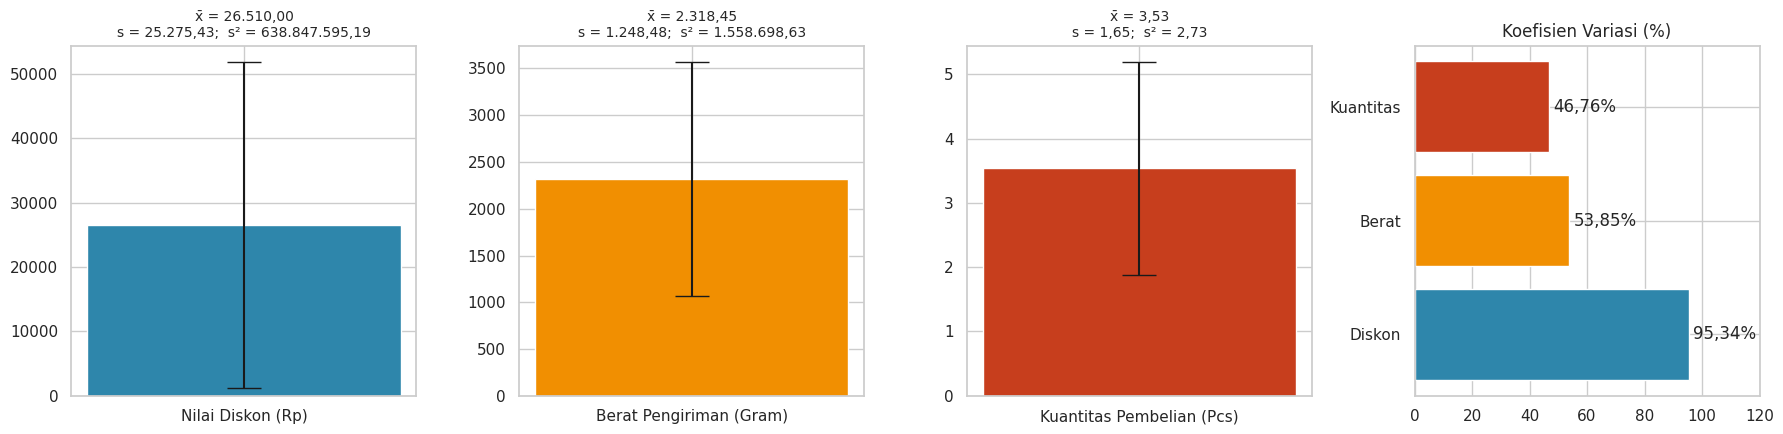

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
for a, k in zip(ax, VAR):
    a.bar([NAMA[k]], [df[k].mean()], yerr=[df[k].std()], capsize=12, width=0.5, color=WARNA[k])
    a.set_title(f"x̄ = {idn(df[k].mean())}\ns = {idn(df[k].std())};  s² = {idn(df[k].var())}", fontsize=10)
cv = tabel_4_2.loc["Koefisien variasi (%)"]
ax[3].barh(["Diskon", "Berat", "Kuantitas"], cv, color=list(WARNA.values()))
ax[3].bar_label(ax[3].containers[0], labels=[f"{idn(v)}%" for v in cv], padding=3)
ax[3].set_xlim(0, 120); ax[3].set_title("Koefisien Variasi (%)")
plt.tight_layout(); simpan(fig, "Gambar_4.4_Rata_SD_Koefisien_Variasi"); plt.show()

---
<a name="tahap3"></a>

## TAHAP 3 — Distribusi Frekuensi Kuantitas Pembelian (RM 2, Laporan 4.4)

<a href="#menu">⬆ Kembali ke MENU</a>
<a name="langkah31"></a>

### Langkah 3.1 — Tabel distribusi frekuensi → **Tabel 4.3**

In [10]:
q = df["Kuantitas_Pembelian_Pcs"]
tabel_4_3 = q.value_counts().sort_index().rename_axis("Kuantitas (pcs)").to_frame("Frekuensi (f)")
tabel_4_3["Frekuensi relatif (%)"] = tabel_4_3["Frekuensi (f)"] / n * 100
tabel_4_3["Frekuensi kumulatif"] = tabel_4_3["Frekuensi (f)"].cumsum()
tabel_4_3["Frekuensi kumulatif relatif (%)"] = tabel_4_3["Frekuensi relatif (%)"].cumsum()
display(tabel_4_3.round(1))

,Frekuensi (f),Frekuensi relatif (%),Frekuensi kumulatif,Frekuensi kumulatif relatif (%)
Kuantitas (pcs),,,,
1,12,2.4,12,2.4
2,138,27.6,150,30.0
3,137,27.4,287,57.4
4,117,23.4,404,80.8
5,37,7.4,441,88.2
6,29,5.8,470,94.0
7,12,2.4,482,96.4
8,9,1.8,491,98.2
9,5,1.0,496,99.2


<a name="langkah32"></a>

### Langkah 3.2 — Bentuk sebaran: modus, *skewness*, dan *kurtosis* (dengan perhitungan manual)
Dengan $z = \dfrac{x-\bar{x}}{s}$: $\;\text{skewness} = \dfrac{n}{(n-1)(n-2)}\sum z^3$, $\;\text{kurtosis} = \dfrac{n(n+1)}{(n-1)(n-2)(n-3)}\sum z^4 - \dfrac{3(n-1)^2}{(n-2)(n-3)}$

In [11]:
z = (q - q.mean()) / q.std()
skew = n / ((n - 1) * (n - 2)) * (z ** 3).sum()
kurt = n * (n + 1) / ((n - 1) * (n - 2) * (n - 3)) * (z ** 4).sum() - 3 * (n - 1) ** 2 / ((n - 2) * (n - 3))

print(f"Modus = {q.mode()[0]} pcs | median = {idn(q.median(), 0)} pcs | rata-rata = {idn(q.mean(), 3)} pcs")
print(f"Σz³ = {idn((z ** 3).sum(), 3)}  →  skewness = {idn(skew, 4)}")
print(f"Σz⁴ = {idn((z ** 4).sum(), 3)}  →  kurtosis = {idn(kurt, 4)}")
print(f"Transaksi berisi 2–4 pcs = {idn(tabel_4_3.loc[2:4, 'Frekuensi relatif (%)'].sum(), 1)}%")

Modus = 2 pcs | median = 3 pcs | rata-rata = 3,534 pcs
Σz³ = 675,672  →  skewness = 1,3595
Σz⁴ = 2.587,172  →  kurtosis = 2,2293
Transaksi berisi 2–4 pcs = 78,4%


<a name="langkah33"></a>

### Langkah 3.3 — Diagram batang frekuensi dan ogive → **Gambar 4.5**

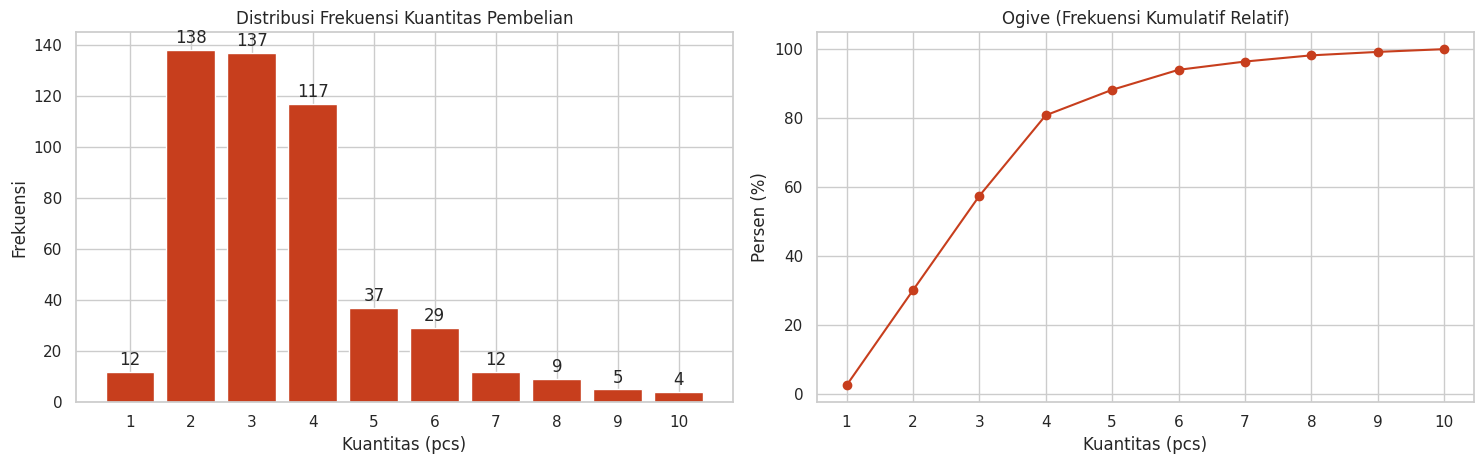

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].bar(tabel_4_3.index, tabel_4_3["Frekuensi (f)"], color=WARNA["Kuantitas_Pembelian_Pcs"])
ax[0].bar_label(ax[0].containers[0], padding=2)
ax[0].set_title("Distribusi Frekuensi Kuantitas Pembelian"); ax[0].set_xlabel("Kuantitas (pcs)"); ax[0].set_ylabel("Frekuensi")
ax[1].plot(tabel_4_3.index, tabel_4_3["Frekuensi kumulatif relatif (%)"], "o-", color=WARNA["Kuantitas_Pembelian_Pcs"])
ax[1].set_title("Ogive (Frekuensi Kumulatif Relatif)"); ax[1].set_xlabel("Kuantitas (pcs)"); ax[1].set_ylabel("Persen (%)")
for a in ax: a.set_xticks(range(1, 11))
plt.tight_layout(); simpan(fig, "Gambar_4.5_Distribusi_Frekuensi_Kuantitas"); plt.show()

---
<a name="tahap4"></a>

## TAHAP 4 — Ukuran Letak (RM 3, Laporan 4.5)

<a href="#menu">⬆ Kembali ke MENU</a>
<a name="langkah41"></a>

### Langkah 4.1 — Ringkasan ukuran letak (dari Tabel 4.2)

In [13]:
letak = ["Minimum", "Kuartil pertama (Q1)", "Median (Q2)", "Kuartil ketiga (Q3)",
         "Maksimum", "Jangkauan (range)", "Jangkauan antarkuartil (IQR)"]
display(tabel_4_2.loc[letak].map(lambda v: idn(v, 2)))

,Nilai_Diskon_Rp,Berat_Pengiriman_Gram,Kuantitas_Pembelian_Pcs
Minimum,"5.000,00","218,00","1,00"
Kuartil pertama (Q1),"10.000,00","1.260,75","2,00"
Median (Q2),"20.000,00","2.312,50","3,00"
Kuartil ketiga (Q3),"35.000,00","3.370,00","4,00"
Maksimum,"150.000,00","4.478,00","10,00"
Jangkauan (range),"145.000,00","4.260,00","9,00"
Jangkauan antarkuartil (IQR),"25.000,00","2.109,25","2,00"


<a name="langkah42"></a>

### Langkah 4.2 — Perhitungan manual kuartil kuantitas pembelian
Data diurutkan, lalu letak $Q_i = 1 + \dfrac{i(n-1)}{4}$ (sama dengan `QUARTILE.INC` di Excel).

In [14]:
urut = np.sort(q)
for i in [1, 2, 3]:
    L = 1 + i * (n - 1) / 4
    b = int(L)
    nilai = urut[b - 1] + (L - b) * (urut[b] - urut[b - 1])
    print(f"Q{i}: letak = {idn(L)} → di antara data ke-{b} ({urut[b - 1]}) dan ke-{b + 1} ({urut[b]}) → Q{i} = {idn(nilai)} pcs")

Q1: letak = 125,75 → di antara data ke-125 (2) dan ke-126 (2) → Q1 = 2,00 pcs
Q2: letak = 250,50 → di antara data ke-250 (3) dan ke-251 (3) → Q2 = 3,00 pcs
Q3: letak = 375,25 → di antara data ke-375 (4) dan ke-376 (4) → Q3 = 4,00 pcs


<a name="langkah43"></a>

### Langkah 4.3 — Boxplot ringkasan lima angka → **Gambar 4.6**
Garis ujung ditarik sampai nilai minimum dan maksimum, sehingga boxplot hanya menggambarkan minimum, Q1, Q2, Q3, dan maksimum.

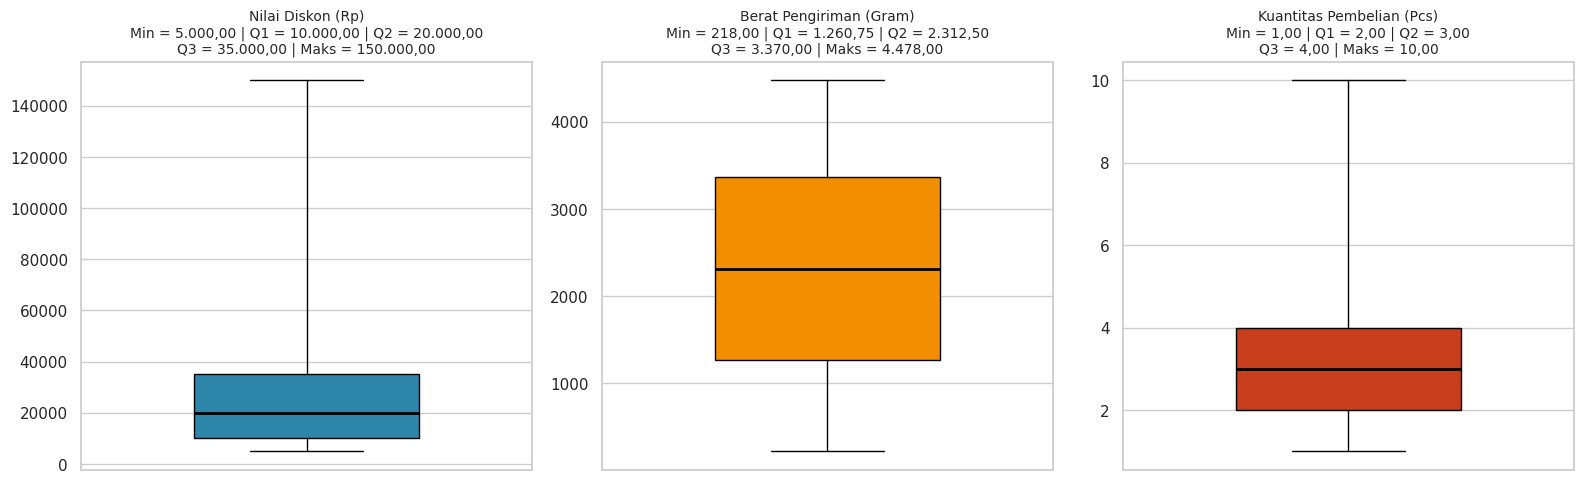

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, k in zip(ax, VAR):
    a.boxplot(df[k], whis=(0, 100), widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=WARNA[k]), medianprops=dict(color="black", lw=2))
    mn, q1, q2, q3, mx = df[k].quantile([0, 0.25, 0.5, 0.75, 1])
    a.set_title(f"{NAMA[k]}\nMin = {idn(mn)} | Q1 = {idn(q1)} | Q2 = {idn(q2)}\nQ3 = {idn(q3)} | Maks = {idn(mx)}", fontsize=10)
    a.set_xticks([])
plt.tight_layout(); simpan(fig, "Gambar_4.6_Boxplot_Ringkasan_Lima_Angka"); plt.show()

---
<a name="tahap5"></a>

## TAHAP 5 — Dashboard dan Menu Interaktif (Laporan 4.6)

<a href="#menu">⬆ Kembali ke MENU</a>
<a name="langkah51"></a>

### Langkah 5.1 — Dashboard hasil analisis → **Gambar 4.7**
Baris 1 = RM 1, baris 2 = RM 2 (ditambah skewness dan kurtosis ketiga variabel), baris 3 = RM 3; kolom paling kanan baris 2 dan 3 = gambaran umum data.

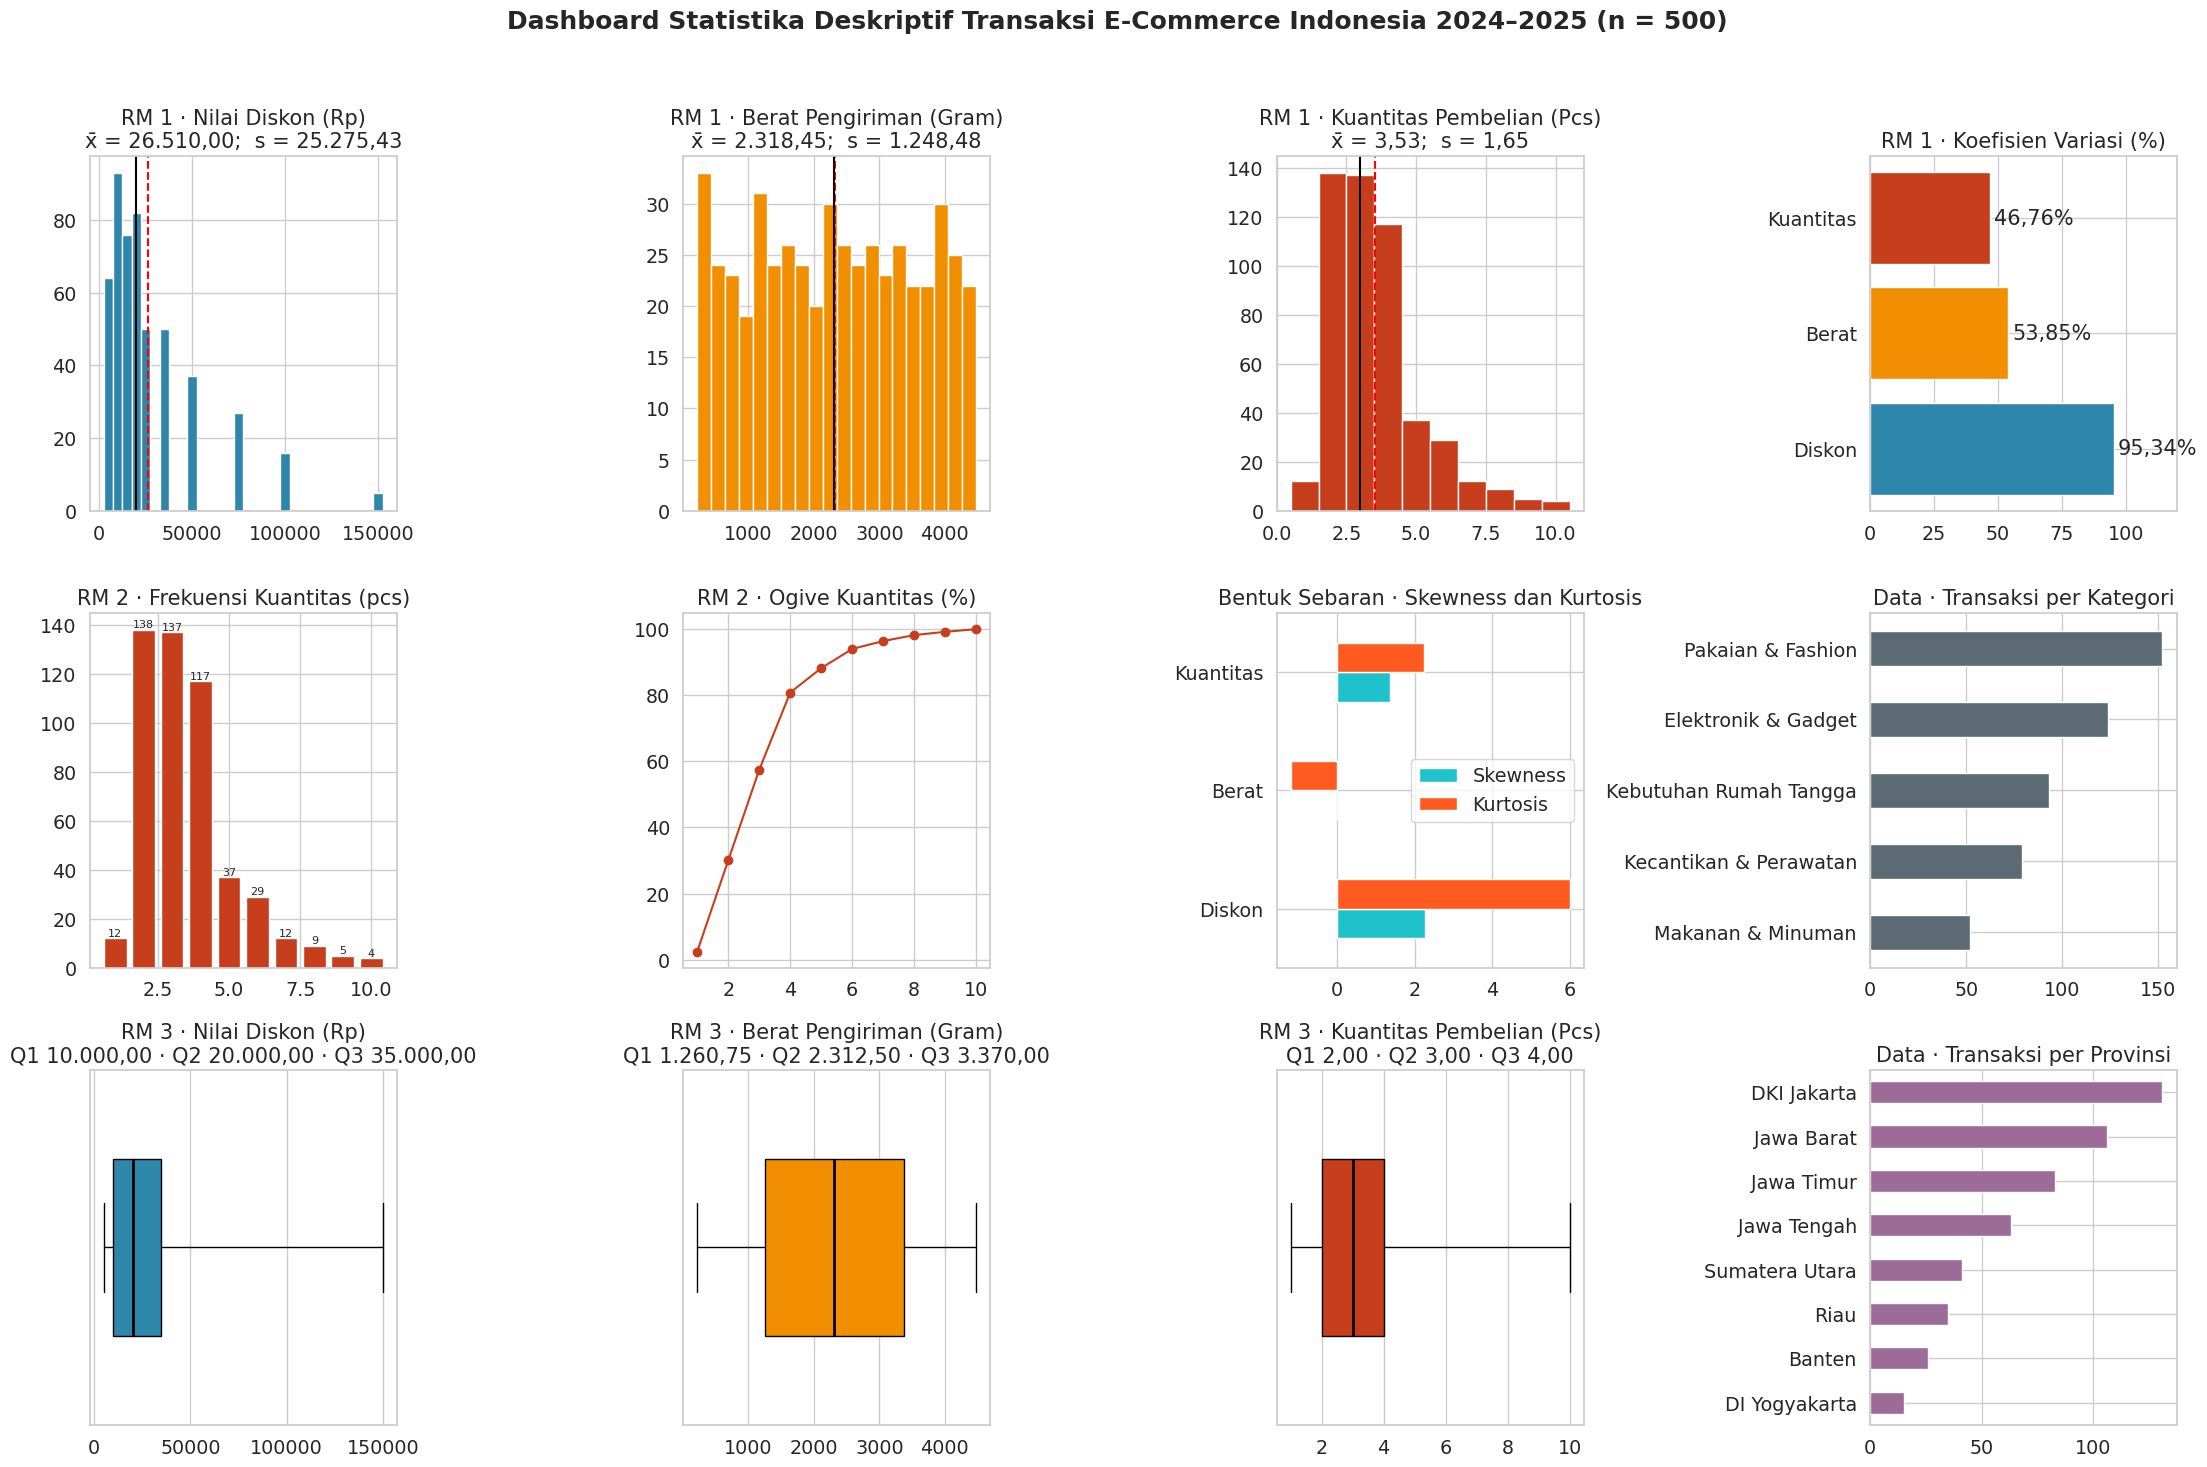

In [16]:
sns.set_context("notebook", font_scale=1.25)   # huruf lebih besar agar dashboard mudah dibaca
fig, ax = plt.subplots(3, 4, figsize=(22, 15))
fig.suptitle("Dashboard Statistika Deskriptif Transaksi E-Commerce Indonesia 2024–2025 (n = 500)", fontsize=18, fontweight="bold")

# Baris 1 (RM 1): histogram ketiga variabel + koefisien variasi
for a, k in zip(ax[0], VAR):
    a.hist(df[k], bins=KELAS[k], color=WARNA[k], edgecolor="white")
    a.axvline(df[k].mean(), color="red", ls="--"); a.axvline(df[k].median(), color="black")
    a.set_title(f"RM 1 · {NAMA[k]}\nx̄ = {idn(df[k].mean())};  s = {idn(df[k].std())}")
ax[0, 3].barh(["Diskon", "Berat", "Kuantitas"], cv, color=list(WARNA.values()))
ax[0, 3].bar_label(ax[0, 3].containers[0], labels=[f"{idn(v)}%" for v in cv], padding=3)
ax[0, 3].set_xlim(0, 120); ax[0, 3].set_title("RM 1 · Koefisien Variasi (%)")

# Baris 2 (RM 2): distribusi frekuensi kuantitas, ogive, skewness dan kurtosis
ax[1, 0].bar(tabel_4_3.index, tabel_4_3["Frekuensi (f)"], color=WARNA["Kuantitas_Pembelian_Pcs"])
ax[1, 0].bar_label(ax[1, 0].containers[0], fontsize=8); ax[1, 0].set_title("RM 2 · Frekuensi Kuantitas (pcs)")
ax[1, 1].plot(tabel_4_3.index, tabel_4_3["Frekuensi kumulatif relatif (%)"], "o-", color=WARNA["Kuantitas_Pembelian_Pcs"])
ax[1, 1].set_title("RM 2 · Ogive Kuantitas (%)")
bentuk = tabel_4_2.loc[["Kemencengan (skewness)", "Keruncingan (kurtosis)"]].T
bentuk.index = ["Diskon", "Berat", "Kuantitas"]; bentuk.columns = ["Skewness", "Kurtosis"]
bentuk.plot.barh(ax=ax[1, 2], color=["#1FC1CB", "#FF5A1F"]); ax[1, 2].set_title("Bentuk Sebaran · Skewness dan Kurtosis")
df["Kategori_Produk"].value_counts().sort_values().plot.barh(ax=ax[1, 3], color="#5C6B73")
ax[1, 3].set_title("Data · Transaksi per Kategori"); ax[1, 3].set_ylabel("")

# Baris 3 (RM 3): boxplot lima angka ketiga variabel
for a, k in zip(ax[2], VAR):
    a.boxplot(df[k], whis=(0, 100), vert=False, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=WARNA[k]), medianprops=dict(color="black", lw=2))
    q1, q2, q3 = df[k].quantile([0.25, 0.5, 0.75])
    a.set_title(f"RM 3 · {NAMA[k]}\nQ1 {idn(q1)} · Q2 {idn(q2)} · Q3 {idn(q3)}"); a.set_yticks([])
df["Provinsi_Tujuan"].value_counts().sort_values().plot.barh(ax=ax[2, 3], color="#9C6B98")
ax[2, 3].set_title("Data · Transaksi per Provinsi"); ax[2, 3].set_ylabel("")

plt.tight_layout(rect=[0, 0, 1, 0.96])
simpan(fig, "Gambar_4.7_Dashboard_Hasil_Analisis"); plt.show()

<a name="langkah52"></a>

### Langkah 5.2 — Dashboard interaktif (tampilan web)
Jalankan sel di bawah, lalu **klik menu di sebelah kiri** untuk berpindah halaman (Ringkasan, RM 1, RM 2, RM 3, Data). Gunakan **filter Kategori, Provinsi, dan Variabel** untuk memperbarui semua kartu angka, grafik, dan tabel secara langsung.

In [20]:
# ===== DASHBOARD INTERAKTIF (tampilan seperti web: sidebar menu + filter + kartu ringkasan + grafik) =====
import ipywidgets as w
from IPython.display import display, HTML, clear_output

SEMUA = "Semua"
KAT  = [SEMUA] + sorted(df["Kategori_Produk"].unique())
PROV = [SEMUA] + sorted(df["Provinsi_Tujuan"].unique())
HALAMAN = ["🏠  Ringkasan", "📊  RM 1 · Rata-rata & Sebaran", "📦  RM 2 · Distribusi Frekuensi",
           "📍  RM 3 · Ukuran Letak", "🗂️  Data & Komposisi"]
state = {"halaman": HALAMAN[0]}

CSS = """<style>
.dbx-head{background:linear-gradient(90deg,#1F3A5F,#2E86AB);color:#fff;padding:16px 22px;border-radius:12px;font-family:sans-serif}
.dbx-head h2{margin:0;font-size:20px;color:#fff}
.dbx-head p{margin:4px 0 0;font-size:13px;color:#fff;opacity:.92}
.dbx-cards{display:flex;gap:12px;flex-wrap:wrap;margin:6px 0 12px;font-family:sans-serif}
.dbx-card{flex:1;min-width:150px;background:#fff;border-radius:10px;padding:10px 14px;box-shadow:0 1px 5px rgba(0,0,0,.25);border-left:6px solid #2E86AB}
.dbx-card .t{font-size:12px;color:#555}.dbx-card .v{font-size:21px;font-weight:700;color:#111}.dbx-card .s{font-size:11px;color:#777}
.dbx-judul{font-family:sans-serif;font-size:17px;font-weight:700;margin:6px 0}
</style>"""

def kartu(items):
    """items = [(judul, nilai, keterangan, warna), ...] -> deretan kartu ringkasan"""
    h = "<div class='dbx-cards'>"
    for judul, nilai, ket, warna in items:
        h += (f"<div class='dbx-card' style='border-left-color:{warna}'><div class='t'>{judul}</div>"
              f"<div class='v'>{nilai}</div><div class='s'>{ket}</div></div>")
    display(HTML(h + "</div>"))

def judul(teks):
    display(HTML(f"<div class='dbx-judul'>{teks}</div>"))

def fmt(k, v, d=2):                         # format angka sesuai satuan variabel
    return idn(v, 0 if k == "Nilai_Diskon_Rp" else d)

# ---------- komponen widget ----------
dd_kat  = w.Dropdown(options=KAT,  value=SEMUA, description="Kategori", layout=w.Layout(width="225px"))
dd_prov = w.Dropdown(options=PROV, value=SEMUA, description="Provinsi", layout=w.Layout(width="225px"))
dd_var  = w.Dropdown(options=[(NAMA[k], k) for k in VAR], description="Variabel", layout=w.Layout(width="225px"))
for d_ in (dd_kat, dd_prov, dd_var):
    d_.style = {"description_width": "62px"}
tombol = [w.Button(description=h, layout=w.Layout(width="225px", height="40px"), tooltip="Klik untuk membuka halaman") for h in HALAMAN]
out = w.Output()

def data_terfilter():
    d = df
    if dd_kat.value != SEMUA:  d = d[d["Kategori_Produk"] == dd_kat.value]
    if dd_prov.value != SEMUA: d = d[d["Provinsi_Tujuan"] == dd_prov.value]
    return d

# ---------- halaman-halaman ----------
def hal_ringkasan(d):
    kartu([("Jumlah transaksi", idn(len(d), 0), f"dari {n} transaksi", "#5C6B73"),
           ("Rata-rata diskon", "Rp " + idn(d[VAR[0]].mean(), 0), "per transaksi", WARNA[VAR[0]]),
           ("Rata-rata berat kirim", idn(d[VAR[1]].mean(), 1) + " g", "per transaksi", WARNA[VAR[1]]),
           ("Rata-rata kuantitas", idn(d[VAR[2]].mean(), 2) + " pcs", "per transaksi", WARNA[VAR[2]])])
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
    for a, k in zip(ax, VAR):
        a.hist(d[k], bins=KELAS[k], color=WARNA[k], edgecolor="white")
        a.axvline(d[k].mean(), color="red", ls="--", lw=2); a.axvline(d[k].median(), color="black", lw=2)
        a.set_title(NAMA[k]); a.set_ylabel("Frekuensi"); a.tick_params(axis="x", labelrotation=30)
    plt.tight_layout(); plt.show()
    judul("Resume singkat (garis merah putus-putus = rata-rata, garis hitam = median)")
    baris = ["Rata-rata (x̄)", "Median (Q2)", "Standar deviasi (s)", "Minimum", "Maksimum"]
    display(d[VAR].apply(resume).loc[baris].rename(columns=NAMA).map(lambda v: idn(v, 2)))

def hal_rm1(d):
    k = dd_var.value; r = resume(d[k])
    kartu([("Rata-rata (x̄)", fmt(k, r["Rata-rata (x̄)"]), NAMA[k], WARNA[k]),
           ("Variansi (s²)", idn(r["Variansi (s²)"], 2), "", WARNA[k]),
           ("Standar deviasi (s)", fmt(k, r["Standar deviasi (s)"]), "", WARNA[k]),
           ("Standard error", idn(r["Standard error (SE)"], 3), "s / √n", WARNA[k]),
           ("Koefisien variasi", idn(r["Koefisien variasi (%)"], 2) + "%", "s / x̄ × 100%", WARNA[k])])
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2, 1]})
    ax[0].hist(d[k], bins=KELAS[k], color=WARNA[k], edgecolor="white")
    ax[0].axvline(d[k].mean(), color="red", ls="--", lw=2, label=f"Rata-rata = {idn(d[k].mean())}")
    ax[0].axvline(d[k].median(), color="black", lw=2, label=f"Median = {idn(d[k].median())}")
    ax[0].set_title(f"Histogram {NAMA[k]}"); ax[0].set_xlabel(NAMA[k]); ax[0].set_ylabel("Frekuensi"); ax[0].legend()
    cv_ = [d[v].std() / d[v].mean() * 100 for v in VAR]
    ax[1].barh(["Diskon", "Berat", "Kuantitas"], cv_, color=[WARNA[v] for v in VAR])
    ax[1].bar_label(ax[1].containers[0], labels=[f"{idn(v)}%" for v in cv_], padding=3)
    ax[1].set_xlim(0, max(cv_) * 1.3); ax[1].set_title("Koefisien Variasi (%) - perbandingan 3 variabel")
    plt.tight_layout(); plt.show()
    judul("Resume statistika deskriptif")
    display(d[VAR].apply(resume).rename(columns=NAMA).map(lambda v: idn(v, 3)))

def hal_rm2(d):
    q = d[VAR[2]]
    tb = q.value_counts().sort_index().rename_axis("Kuantitas (pcs)").to_frame("Frekuensi (f)")
    tb["Frekuensi relatif (%)"] = tb["Frekuensi (f)"] / len(q) * 100
    tb["Frekuensi kumulatif"] = tb["Frekuensi (f)"].cumsum()
    tb["Frekuensi kumulatif relatif (%)"] = tb["Frekuensi relatif (%)"].cumsum()
    p24 = tb.loc[(tb.index >= 2) & (tb.index <= 4), "Frekuensi relatif (%)"].sum()
    kartu([("Modus", f"{q.mode()[0]} pcs", f"{idn(tb['Frekuensi relatif (%)'].max(), 1)}% transaksi", WARNA[VAR[2]]),
           ("Rata-rata", idn(q.mean(), 2) + " pcs", f"median {idn(q.median(), 0)} pcs", WARNA[VAR[2]]),
           ("Skewness", idn(q.skew(), 3), "kemencengan", WARNA[VAR[2]]),
           ("Kurtosis", idn(q.kurt(), 3), "keruncingan", WARNA[VAR[2]]),
           ("Transaksi 2–4 pcs", idn(p24, 1) + "%", "frekuensi relatif", WARNA[VAR[2]])])
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    ax[0].bar(tb.index, tb["Frekuensi (f)"], color=WARNA[VAR[2]]); ax[0].bar_label(ax[0].containers[0], padding=2)
    ax[0].set_title("Distribusi Frekuensi Kuantitas Pembelian"); ax[0].set_xlabel("Kuantitas (pcs)"); ax[0].set_ylabel("Frekuensi")
    ax[1].plot(tb.index, tb["Frekuensi kumulatif relatif (%)"], "o-", color=WARNA[VAR[2]])
    ax[1].set_title("Ogive (Frekuensi Kumulatif Relatif)"); ax[1].set_xlabel("Kuantitas (pcs)"); ax[1].set_ylabel("Persen (%)")
    for a in ax: a.set_xticks(range(1, 11))
    plt.tight_layout(); plt.show()
    judul("Tabel distribusi frekuensi")
    display(tb.round(1))

def hal_rm3(d):
    k = dd_var.value; r = resume(d[k])
    kartu([("Minimum", fmt(k, r["Minimum"]), "", "#5C6B73"), ("Q1", fmt(k, r["Kuartil pertama (Q1)"]), "kuartil pertama", WARNA[k]),
           ("Median (Q2)", fmt(k, r["Median (Q2)"]), "", WARNA[k]), ("Q3", fmt(k, r["Kuartil ketiga (Q3)"]), "kuartil ketiga", WARNA[k]),
           ("Maksimum", fmt(k, r["Maksimum"]), "", "#5C6B73"), ("IQR", fmt(k, r["Jangkauan antarkuartil (IQR)"]), "Q3 − Q1", "#9C6B98")])
    fig, ax = plt.subplots(figsize=(13, 3))
    ax.boxplot(d[k], whis=(0, 100), vert=False, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=WARNA[k]), medianprops=dict(color="black", lw=2))
    ax.set_title(f"Boxplot lima angka - {NAMA[k]}"); ax.set_yticks([]); ax.set_xlabel(NAMA[k])
    plt.tight_layout(); plt.show()
    judul("Ukuran letak ketiga variabel")
    display(d[VAR].apply(resume).loc[letak].rename(columns=NAMA).map(lambda v: idn(v, 2)))

def hal_data(d):
    kartu([("Transaksi", idn(len(d), 0), "sesuai filter", "#5C6B73"),
           ("Kategori produk", str(d["Kategori_Produk"].nunique()), "kategori", "#2E86AB"),
           ("Provinsi tujuan", str(d["Provinsi_Tujuan"].nunique()), "provinsi", "#9C6B98"),
           ("Periode", f"{d['Tanggal_Transaksi'].min():%b %Y} – {d['Tanggal_Transaksi'].max():%b %Y}", "tanggal transaksi", "#F18F01")])
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    d["Kategori_Produk"].value_counts().sort_values().plot.barh(ax=ax[0], color="#5C6B73")
    d["Provinsi_Tujuan"].value_counts().sort_values().plot.barh(ax=ax[1], color="#9C6B98")
    ax[0].set_title("Transaksi per Kategori Produk"); ax[1].set_title("Transaksi per Provinsi Tujuan")
    for a in ax: a.bar_label(a.containers[0], padding=3); a.set_ylabel(""); a.set_xlabel("Jumlah transaksi")
    plt.tight_layout(); plt.show()
    judul("Cuplikan data (15 baris pertama sesuai filter)")
    display(d.head(15))

PETA = {HALAMAN[0]: hal_ringkasan, HALAMAN[1]: hal_rm1, HALAMAN[2]: hal_rm2, HALAMAN[3]: hal_rm3, HALAMAN[4]: hal_data}

def render(*_):
    for b in tombol:                                       # tombol halaman aktif berwarna biru
        b.button_style = "primary" if b.description == state["halaman"] else ""
    dd_var.disabled = state["halaman"] not in (HALAMAN[1], HALAMAN[3])   # variabel hanya dipakai RM 1 dan RM 3
    d = data_terfilter()
    with out:
        clear_output(wait=True)
        display(HTML(f"<div class='dbx-judul'>{state['halaman'].strip()}</div>"))
        if len(d) < 5:
            display(HTML("<b>⚠️ Data hasil filter terlalu sedikit (kurang dari 5 transaksi). Ubah filter Kategori / Provinsi.</b>"))
            return
        PETA[state["halaman"]](d)
        plt.close("all")

def klik(b):
    state["halaman"] = b.description
    render()

for b in tombol: b.on_click(klik)
for d_ in (dd_kat, dd_prov, dd_var): d_.observe(render, names="value")

sidebar = w.VBox([w.HTML("<b style='font-family:sans-serif'>☰ MENU</b>")] + tombol +
                 [w.HTML("<hr style='margin:8px 0'><b style='font-family:sans-serif'>🔎 FILTER</b>"), dd_kat, dd_prov, dd_var],
                 layout=w.Layout(width="250px", padding="10px", border="1px solid #bbb", border_radius="10px"))
header = w.HTML(CSS + "<div class='dbx-head'><h2>📊 Dashboard Statistika Deskriptif E-Commerce Indonesia 2024–2025</h2>"
                "<p>Klik menu di kiri untuk berpindah halaman · gunakan filter Kategori / Provinsi / Variabel untuk memperbarui semua angka dan grafik</p></div>")
display(w.VBox([header, w.HBox([sidebar, w.VBox([out], layout=w.Layout(flex="1 1 auto", padding="0 0 0 14px"))])]))
render()

---
<a name="tahap6"></a>

## TAHAP 6 — Ringkasan Jawaban dan Ekspor File (Laporan 4.7 dan Bab 5)

<a href="#menu">⬆ Kembali ke MENU</a>
<a name="langkah61"></a>

### Langkah 6.1 — Ringkasan jawaban rumusan masalah

In [18]:
t = tabel_4_2
print("RM 1 — Rata-rata, variansi, standar deviasi")
for k in VAR:
    print(f"  {NAMA[k]}: x̄ = {idn(t.loc['Rata-rata (x̄)', k])}, s² = {idn(t.loc['Variansi (s²)', k])}, "
          f"s = {idn(t.loc['Standar deviasi (s)', k])}, CV = {idn(t.loc['Koefisien variasi (%)', k])}%")

print("\nRM 2 — Distribusi frekuensi kuantitas pembelian")
print(f"  Modus {q.mode()[0]} pcs ({idn(tabel_4_3['Frekuensi relatif (%)'].max(), 1)}%), "
      f"2–4 pcs = {idn(tabel_4_3.loc[2:4, 'Frekuensi relatif (%)'].sum(), 1)}%, "
      f"skewness = {idn(q.skew(), 3)}, kurtosis = {idn(q.kurt(), 3)}")

print("\nRM 3 — Ukuran letak")
for k in VAR:
    print(f"  {NAMA[k]}: min = {idn(t.loc['Minimum', k])}, Q1 = {idn(t.loc['Kuartil pertama (Q1)', k])}, "
          f"Q2 = {idn(t.loc['Median (Q2)', k])}, Q3 = {idn(t.loc['Kuartil ketiga (Q3)', k])}, "
          f"maks = {idn(t.loc['Maksimum', k])}, IQR = {idn(t.loc['Jangkauan antarkuartil (IQR)', k])}")

RM 1 — Rata-rata, variansi, standar deviasi
  Nilai Diskon (Rp): x̄ = 26.510,00, s² = 638.847.595,19, s = 25.275,43, CV = 95,34%
  Berat Pengiriman (Gram): x̄ = 2.318,45, s² = 1.558.698,63, s = 1.248,48, CV = 53,85%
  Kuantitas Pembelian (Pcs): x̄ = 3,53, s² = 2,73, s = 1,65, CV = 46,76%

RM 2 — Distribusi frekuensi kuantitas pembelian
  Modus 2 pcs (27,6%), 2–4 pcs = 78,4%, skewness = 1,359, kurtosis = 2,229

RM 3 — Ukuran letak
  Nilai Diskon (Rp): min = 5.000,00, Q1 = 10.000,00, Q2 = 20.000,00, Q3 = 35.000,00, maks = 150.000,00, IQR = 25.000,00
  Berat Pengiriman (Gram): min = 218,00, Q1 = 1.260,75, Q2 = 2.312,50, Q3 = 3.370,00, maks = 4.478,00, IQR = 2.109,25
  Kuantitas Pembelian (Pcs): min = 1,00, Q1 = 2,00, Q2 = 3,00, Q3 = 4,00, maks = 10,00, IQR = 2,00


<a name="langkah62"></a>

### Langkah 6.2 — Ekspor tabel ke Excel dan unduh semua file

In [19]:
import shutil
with pd.ExcelWriter("Tabel_Laporan_3TIA_08.xlsx") as w:
    tabel_4_1.to_excel(w, sheet_name="Tabel 4.1", index=False)
    tabel_4_2.to_excel(w, sheet_name="Tabel 4.2")
    tabel_4_3.to_excel(w, sheet_name="Tabel 4.3")
shutil.make_archive("output_laporan", "zip", "output_laporan")
print(sorted(os.listdir("output_laporan")))

try:                                       # unduh otomatis jika dijalankan di Colab
    from google.colab import files
    files.download("output_laporan.zip"); files.download("Tabel_Laporan_3TIA_08.xlsx")
except ImportError:
    print("File tersimpan di folder kerja.")

['Gambar_4.1_Komposisi_Kategori_Provinsi.png', 'Gambar_4.2_Jumlah_Transaksi_per_Bulan.png', 'Gambar_4.3_Histogram_Variabel_Utama.png', 'Gambar_4.4_Rata_SD_Koefisien_Variasi.png', 'Gambar_4.5_Distribusi_Frekuensi_Kuantitas.png', 'Gambar_4.6_Boxplot_Ringkasan_Lima_Angka.png', 'Gambar_4.7_Dashboard_Hasil_Analisis.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>